# Data Augmentation

**Idea:** show the network randomly flipped and shifted copies of the training images, so it sees more variety.


In [ ]:
import os, time, copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms


torch.manual_seed(42)
np.random.seed(42)

from google.colab import drive
drive.mount("/content/drive")
os.chdir("/content/drive/MyDrive")
os.makedirs("data", exist_ok=True)
os.makedirs("outputs", exist_ok=True)

print("PyTorch version:", torch.__version__)

Mounted at /content/drive
PyTorch version: 2.11.0+cpu


In [ ]:
# CIFAR-10: 32x32 color pictures
mean, std = (0.4914, 0.4822, 0.4465), (0.2470, 0.2435, 0.2616)
plain_tf = transforms.Compose([transforms.ToTensor(), transforms.Normalize(mean, std)])

In [ ]:
# Augmentation is only used for training. Validation and test images stay unchanged.
aug_tf = transforms.Compose([
    transforms.RandomCrop(32, padding=4),   # randomly shift the picture
    transforms.RandomHorizontalFlip(),      # randomly mirror it
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])

plain_full = datasets.CIFAR10("data", train=True, download=True, transform=plain_tf)
aug_full = datasets.CIFAR10("data", train=True, download=True, transform=aug_tf)
test_data = datasets.CIFAR10("data", train=False, download=True, transform=plain_tf)

# Same image indices for both versions, so the only difference is the augmentation
idx = np.random.permutation(len(plain_full))
train_ids = idx[:10000].tolist()
val_ids = idx[10000:12000].tolist()

plain_train_loader = DataLoader(Subset(plain_full, train_ids), batch_size=64, shuffle=True)
aug_train_loader = DataLoader(Subset(aug_full, train_ids), batch_size=64, shuffle=True)
val_loader = DataLoader(Subset(plain_full, val_ids), batch_size=64)
test_loader = DataLoader(test_data, batch_size=64)

In [ ]:
# A small convolutional network for CIFAR-10
class SmallCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
        )
        self.classifier = nn.Sequential(nn.Flatten(), nn.Linear(64 * 8 * 8, 128), nn.ReLU(), nn.Linear(128, 10))

    def forward(self, x):
        return self.classifier(self.features(x))

In [ ]:
loss_fn = nn.CrossEntropyLoss()

def evaluate(model, loader):
    """Return (average loss, accuracy) of the model on a dataset."""
    model.eval()
    correct, total, loss_sum = 0, 0, 0.0
    with torch.no_grad():
        for x, y in loader:
            out = model(x)
            loss_sum += loss_fn(out, y).item() * len(y)
            correct += (out.argmax(1) == y).sum().item()
            total += len(y)
    return loss_sum / total, correct / total

def train(model, loader, epochs=3, lr=1e-3, weight_decay=0.0, make_scheduler=None):
    """Train with Adam. Returns a table of per-epoch results and the training time."""
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    scheduler = make_scheduler(optimizer) if make_scheduler else None
    history = []
    start = time.time()
    for epoch in range(epochs):
        model.train()
        loss_sum, seen = 0.0, 0
        for x, y in loader:
            optimizer.zero_grad()
            loss = loss_fn(model(x), y)
            loss.backward()
            optimizer.step()
            loss_sum += loss.item() * len(y)
            seen += len(y)
        val_loss, val_acc = evaluate(model, val_loader)
        history.append({"epoch": epoch + 1, "train_loss": loss_sum / seen, "val_loss": val_loss,
                        "val_acc": val_acc, "lr": optimizer.param_groups[0]["lr"]})
        print(f"epoch {epoch+1}/{epochs}  train_loss={loss_sum/seen:.4f}  val_loss={val_loss:.4f}  val_acc={val_acc:.4f}")
        if scheduler:
            scheduler.step()
    return pd.DataFrame(history), time.time() - start

## Train the same CNN with and without augmentation

In [ ]:
rows = []
for name, loader in [("baseline", plain_train_loader), ("augmented", aug_train_loader)]:
    print("---", name)
    torch.manual_seed(42)
    model = SmallCNN()
    hist, secs = train(model, loader, epochs=2)
    test_loss, test_acc = evaluate(model, test_loader)
    rows.append({"condition": name, "test_accuracy": test_acc, "test_loss": test_loss, "training_seconds": secs})

results = pd.DataFrame(rows)
results.to_csv("outputs/augmentation_results.csv", index=False)
print(results)

--- baseline
epoch 1/2  train_loss=1.7222  val_loss=1.4291  val_acc=0.4695
epoch 2/2  train_loss=1.3086  val_loss=1.2841  val_acc=0.5285
--- augmented
epoch 1/2  train_loss=1.8681  val_loss=1.5708  val_acc=0.4205
epoch 2/2  train_loss=1.5473  val_loss=1.3980  val_acc=0.4880
   condition  test_accuracy  test_loss  training_seconds
0   baseline         0.5357   1.289844         25.584208
1  augmented         0.5020   1.389334         26.801982


## Look at some augmented images

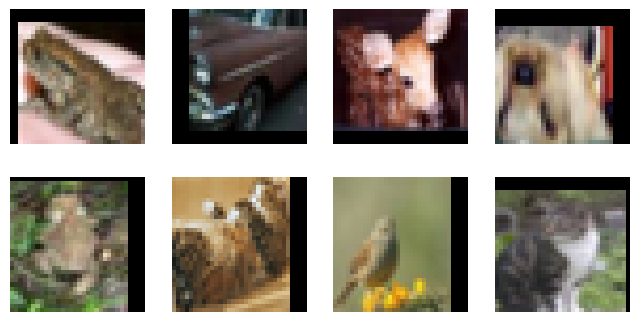

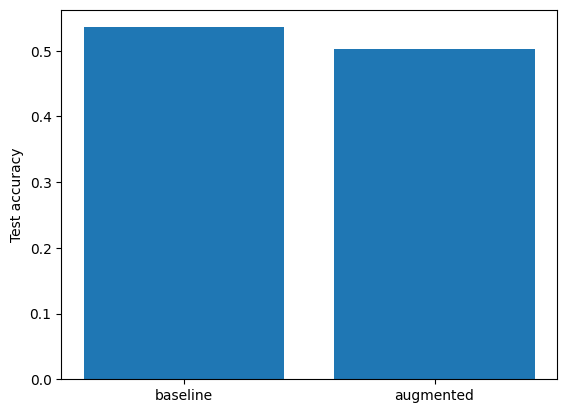

In [ ]:
images, _ = next(iter(aug_train_loader))
mean_t = torch.tensor(mean).view(3, 1, 1)
std_t = torch.tensor(std).view(3, 1, 1)

fig, axes = plt.subplots(2, 4, figsize=(8, 4))
for ax, img in zip(axes.flat, images[:8]):
    img = (img * std_t + mean_t).clamp(0, 1)   # undo the normalization so colors look right
    ax.imshow(img.permute(1, 2, 0))
    ax.axis("off")

plt.savefig("outputs/augmented_images.png", dpi=150, bbox_inches="tight")
plt.show()

plt.bar(results["condition"], results["test_accuracy"])
plt.ylabel("Test accuracy")
plt.savefig("outputs/accuracy_comparison.png", dpi=150, bbox_inches="tight")
plt.show()